# ***Importing Libraries***

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)
import warnings
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ***Exploratory Data Analysis (EDA)***

In [4]:
# Dataset: Telco Customer Churn (Kaggle: blastchar/telco-customer-churn)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [6]:
df.shape

(7043, 21)

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [8]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [10]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.isnull().sum()/df.shape[0]*100

,0
customerID,0.0
gender,0.0
SeniorCitizen,0.0
Partner,0.0
Dependents,0.0
tenure,0.0
PhoneService,0.0
MultipleLines,0.0
InternetService,0.0
OnlineSecurity,0.0


In [13]:
# TotalCharges is stored as text because some rows contain a blank space
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].isnull().sum()

np.int64(11)

In [14]:
# These rows are new customers (tenure = 0) who were not charged yet
df[df['TotalCharges'].isnull()][['tenure','MonthlyCharges','TotalCharges','Churn']]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [15]:
(df==0).sum()

,0
customerID,0
gender,0
SeniorCitizen,5901
Partner,0
Dependents,0
tenure,11
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [16]:
# Target distribution (imbalanced)
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


# *Data Visaulization*

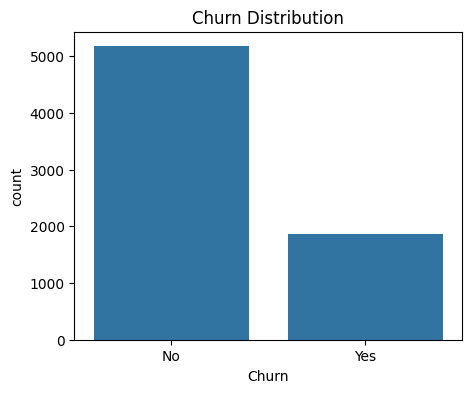

In [17]:
plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

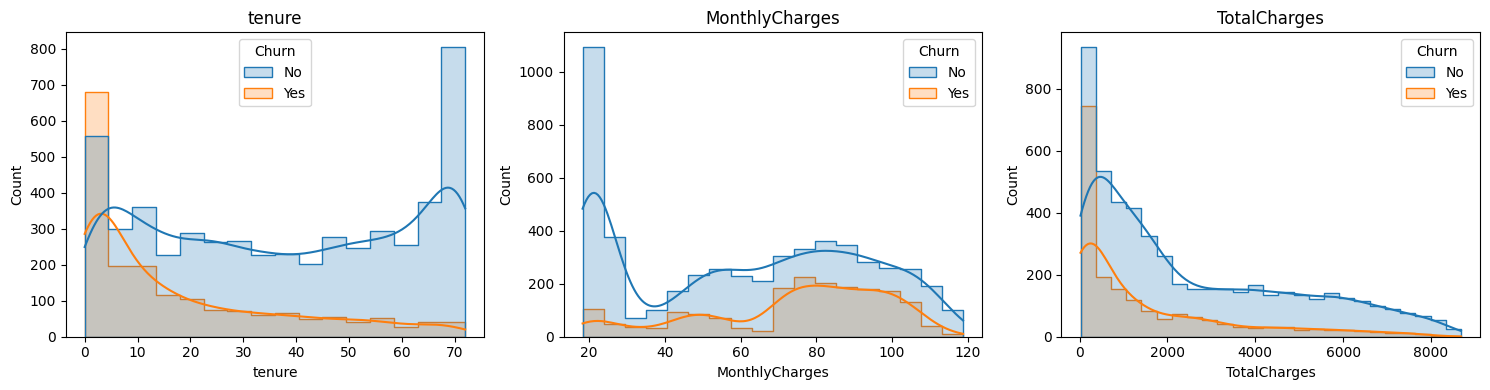

In [18]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

plt.figure(figsize=(15,4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.histplot(data=df, x=col, hue='Churn', kde=True, element='step')
    plt.title(col)
plt.tight_layout()
plt.show()

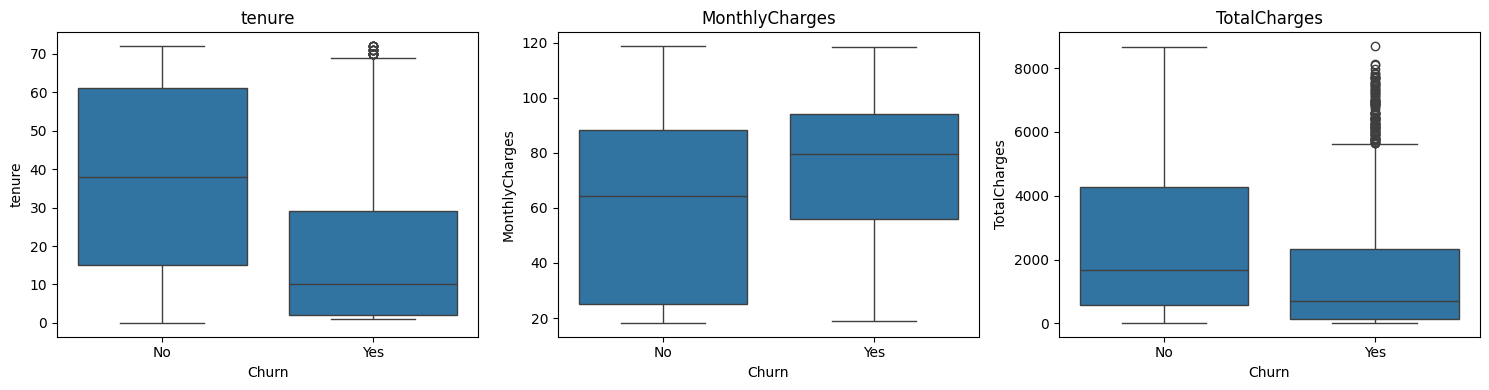

In [19]:
plt.figure(figsize=(15,4))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(x='Churn', y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

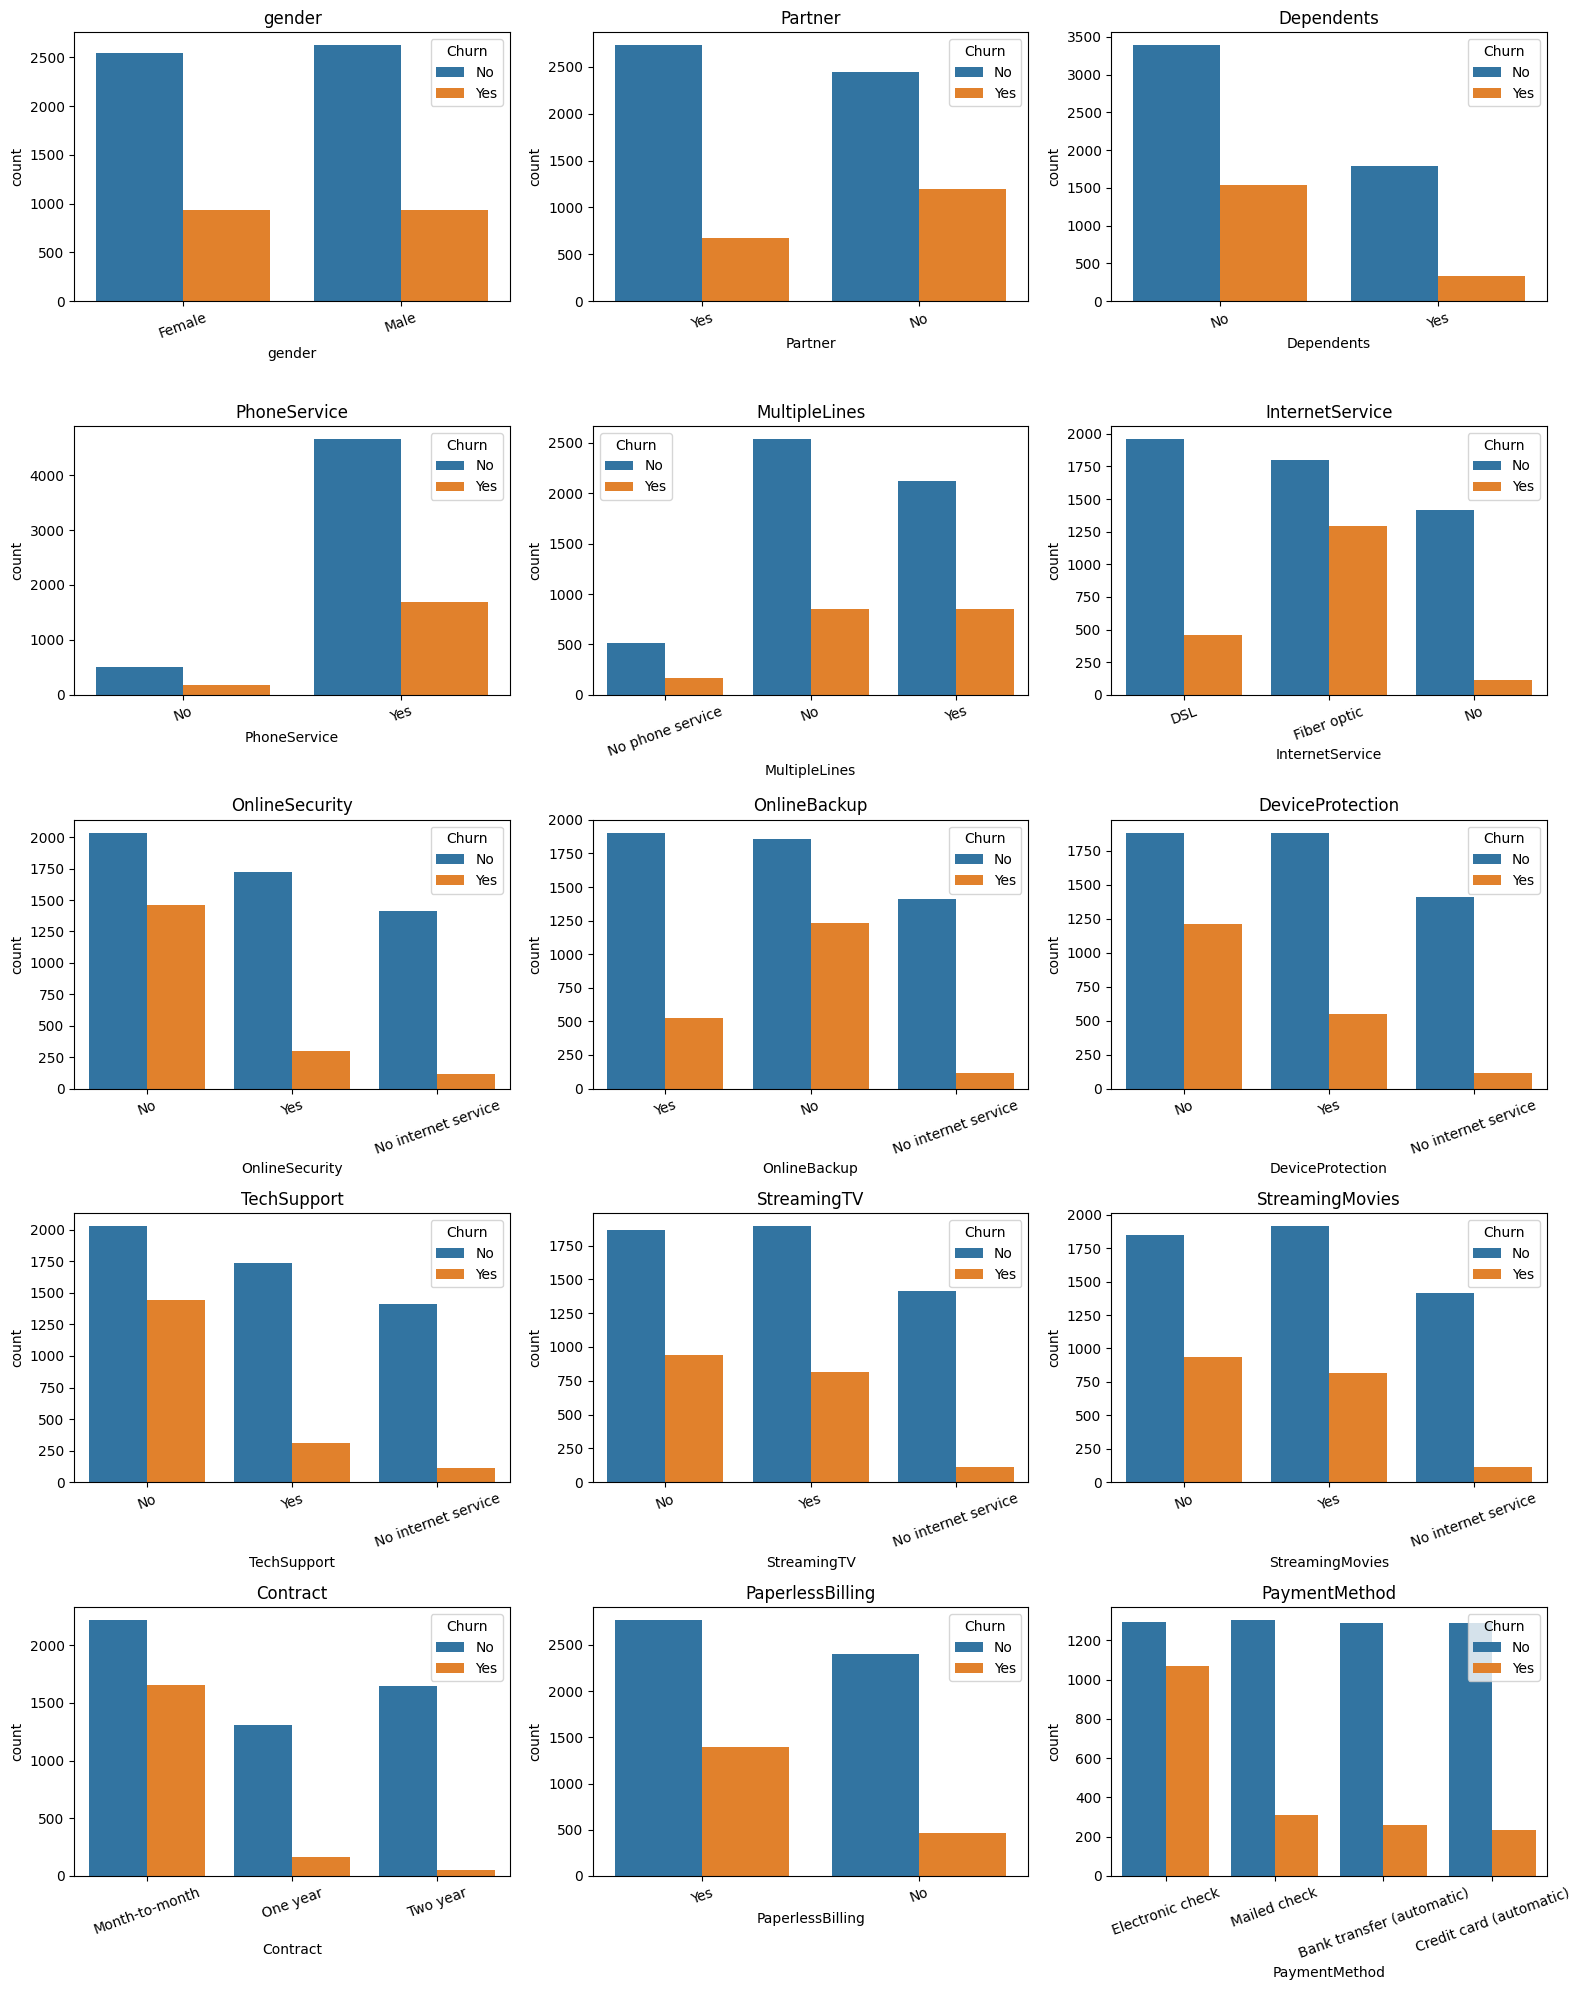

In [20]:
cat_cols_plot = [c for c in df.select_dtypes(include='object').columns if c not in ['customerID', 'Churn']]
n_cols = 3
n_rows = int(np.ceil(len(cat_cols_plot) / n_cols))

plt.figure(figsize=(16, 4 * n_rows))
for i, col in enumerate(cat_cols_plot, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.countplot(x=col, hue='Churn', data=df)
    plt.title(col)
    plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [21]:
# Churn rate per category
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print(df.groupby(col)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).round(2))
    print()

Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64



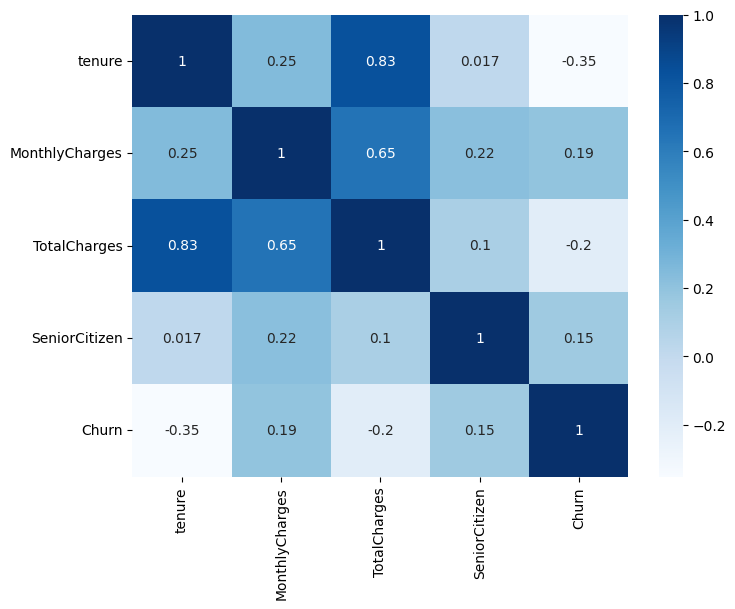

In [22]:
plt.figure(figsize=(8,6))
sns.heatmap(df[num_cols + ['SeniorCitizen']].assign(Churn=(df['Churn']=='Yes').astype(int)).corr(),
            annot=True, cmap='Blues')
plt.show()

# ***Data Preprocessing***

In [23]:
df.drop('customerID', axis=1, inplace=True)

In [24]:
# Only 11 rows have a missing TotalCharges, so dropping them is safe
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(7032, 20)

In [25]:
# Target to 0/1
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

In [26]:
X = df.drop('Churn', axis=1)
y = df['Churn']

In [27]:
# stratify keeps the same churn ratio in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=SEED, stratify=y_train
)
print(X_train.shape, X_val.shape, X_test.shape)

(4781, 19) (844, 19) (1407, 19)


In [28]:
num_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_features = [c for c in X.columns if c not in num_features]

# fitted on train only to avoid data leakage
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary', sparse_output=False), cat_features)
])

X_train_p = preprocessor.fit_transform(X_train)
X_val_p   = preprocessor.transform(X_val)
X_test_p  = preprocessor.transform(X_test)

print(X_train_p.shape)

(4781, 40)


# ***Baseline Models (Classical ML)***

In [29]:
# Baselines to compare the ANN against.
# Accuracy is misleading with imbalanced data, so we use ROC-AUC for tuning and track F1 / Recall too.
X_train_full = np.vstack([X_train_p, X_val_p])
y_train_full = pd.concat([y_train, y_val])

pos_weight = (y_train_full == 0).sum() / (y_train_full == 1).sum()

models = {
    "LogisticRegression": {
        "model": LogisticRegression(max_iter=2000, class_weight='balanced'),
        "params": {"C": [0.01, 0.1, 1, 10]}
    },
    "KNN": {
        "model": KNeighborsClassifier(),
        "params": {"n_neighbors": [5, 9, 15]}
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
        "params": {"max_depth": [3, 5, 10]}
    },
    "RandomForest": {
        "model": RandomForestClassifier(class_weight='balanced', random_state=SEED),
        "params": {"n_estimators": [200, 400], "max_depth": [5, 10, None]}
    },
    "GradientBoosting": {
        "model": GradientBoostingClassifier(random_state=SEED),
        "params": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}
    },
    "XGBoost": {
        "model": XGBClassifier(eval_metric='logloss', scale_pos_weight=pos_weight, verbosity=0, random_state=SEED),
        "params": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]}
    },
    "LightGBM": {
        "model": LGBMClassifier(class_weight='balanced', random_state=SEED, verbose=-1),
        "params": {"n_estimators": [100, 200], "learning_rate": [0.05, 0.1]}
    },
    "SVC": {
        "model": SVC(probability=True, class_weight='balanced', random_state=SEED),
        "params": {"C": [0.1, 1, 10]}
    }
}

In [30]:
results = []

for name, config in models.items():

    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        cv=5,
        scoring='roc_auc',
        n_jobs=-1
    )

    grid.fit(X_train_full, y_train_full)

    best_model = grid.best_estimator_

    y_pred = best_model.predict(X_test_p)
    y_prob = best_model.predict_proba(X_test_p)[:, 1]

    results.append({
        "Model": name,
        "Best Params": grid.best_params_,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

In [31]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Best Params,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.733475,0.499190,0.823529,0.621594,0.840837
1,GradientBoosting,"{'learning_rate': 0.05, 'n_estimators': 100}",0.793177,0.637874,0.513369,0.568889,0.838484
2,LightGBM,"{'learning_rate': 0.05, 'n_estimators': 100}",0.744136,0.512238,0.783422,0.619450,0.836049
3,LogisticRegression,{'C': 10},0.724236,0.488487,0.794118,0.604888,0.834511
4,RandomForest,"{'max_depth': 5, 'n_estimators': 400}",0.717839,0.481054,0.780749,0.595311,0.833910
5,DecisionTree,{'max_depth': 5},0.733475,0.499160,0.794118,0.613003,0.827567
6,SVC,{'C': 0.1},0.729211,0.494215,0.799465,0.610827,0.821838
7,KNN,{'n_neighbors': 15},0.771855,0.573816,0.550802,0.562074,0.815421


# ***Building the ANN***

In [32]:
# Class weights: the model is penalised more for missing a churner
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))
class_weights

{np.int64(0): np.float64(0.681054131054131),
 np.int64(1): np.float64(1.8808025177025964)}

In [33]:
def build_ann(input_dim, units=(64, 32, 16), dropout=0.3, lr=1e-3):
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for u in units:
        model.add(layers.Dense(u, activation='relu', kernel_initializer='he_normal'))
        model.add(layers.BatchNormalization())
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')]
    )
    return model

model = build_ann(X_train_p.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,697 (22.25 KB)

 Trainable params: 5,473 (21.38 KB)

 Non-trainable params: 224 (896.00 B)

In [34]:
callbacks = [
    EarlyStopping(monitor='val_auc', mode='max', patience=15, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)
]

history = model.fit(
    X_train_p, y_train,
    validation_data=(X_val_p, y_val),
    epochs=200,
    batch_size=64,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.6110 - auc: 0.6701 - loss: 0.7348 - recall: 0.6522 - val_accuracy: 0.7287 - val_auc: 0.7968 - val_loss: 0.5395 - val_recall: 0.7188 - learning_rate: 0.0010
Epoch 2/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6867 - auc: 0.7698 - loss: 0.6041 - recall: 0.7396 - val_accuracy: 0.7346 - val_auc: 0.8158 - val_loss: 0.5205 - val_recall: 0.7232 - learning_rate: 0.0010
Epoch 3/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7095 - auc: 0.7855 - loss: 0.5794 - recall: 0.7183 - val_accuracy: 0.7464 - val_auc: 0.8213 - val_loss: 0.5135 - val_recall: 0.7366 - learning_rate: 0.0010
Epoch 4/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7191 - auc: 0.7996 - loss: 0.5551 - recall: 0.7419 - val_accuracy: 0.7500 - val_auc: 0.8237 - val_loss: 0.5228 - val_recall: 0.7679 - learning_rate: 0.0010
Epoch 5/200
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7373 - auc: 0.8180 - loss: 0.5303 - recall: 0.76

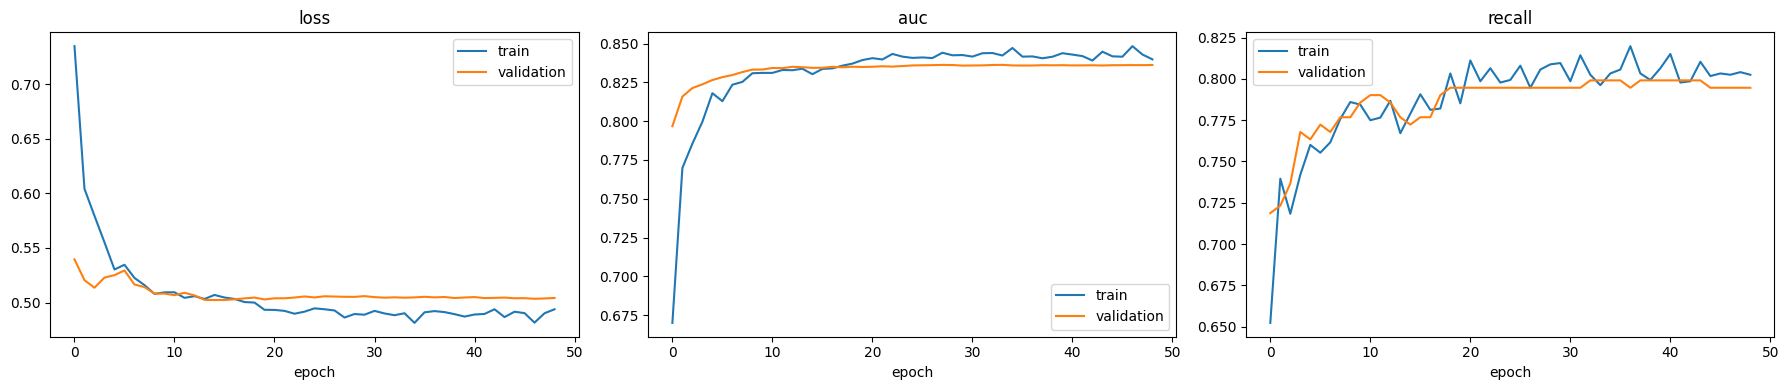

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

for ax, metric in zip(axes, ['loss', 'auc', 'recall']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_title(metric)
    ax.set_xlabel('epoch')
    ax.legend()

plt.tight_layout()
plt.show()

# ***Evaluating the ANN***

In [36]:
y_prob_ann = model.predict(X_test_p).ravel()
y_pred_ann = (y_prob_ann >= 0.5).astype(int)

print(classification_report(y_test, y_pred_ann, target_names=['Stayed', 'Churned']))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_ann))

44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
              precision    recall  f1-score   support

      Stayed       0.91      0.69      0.78      1033
     Churned       0.49      0.80      0.60       374

    accuracy                           0.72      1407
   macro avg       0.70      0.75      0.69      1407
weighted avg       0.79      0.72      0.74      1407

ROC-AUC: 0.8327116906782075


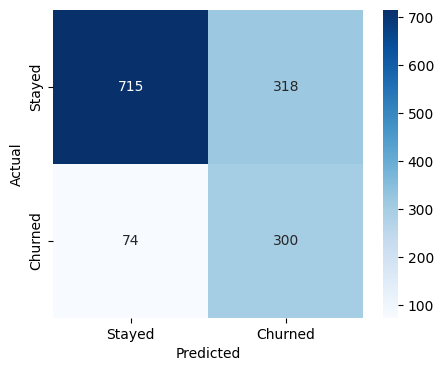

In [37]:
cm = confusion_matrix(y_test, y_pred_ann)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Best threshold: 0.56


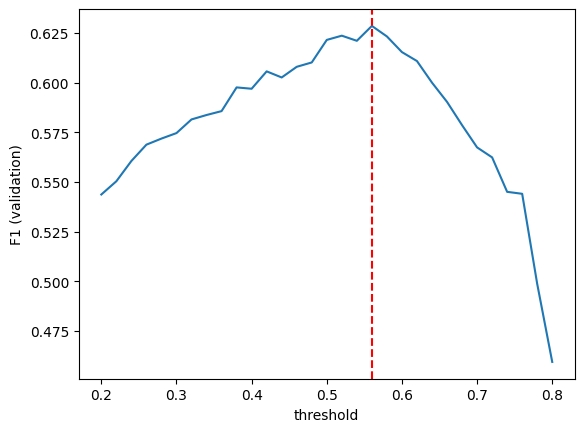

In [38]:
# Threshold tuning: the default 0.5 is not always the best for imbalanced data.
# Here we pick the threshold that maximises F1 on the VALIDATION set (not the test set).
y_val_prob = model.predict(X_val_p).ravel()

thresholds = np.arange(0.2, 0.8, 0.02)
f1_scores = [f1_score(y_val, (y_val_prob >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1_scores))])
print("Best threshold:", round(best_threshold, 2))

plt.plot(thresholds, f1_scores)
plt.axvline(best_threshold, color='r', linestyle='--')
plt.xlabel('threshold')
plt.ylabel('F1 (validation)')
plt.show()

In [39]:
y_pred_tuned = (y_prob_ann >= best_threshold).astype(int)
print(classification_report(y_test, y_pred_tuned, target_names=['Stayed', 'Churned']))

              precision    recall  f1-score   support

      Stayed       0.89      0.76      0.82      1033
     Churned       0.52      0.74      0.61       374

    accuracy                           0.75      1407
   macro avg       0.71      0.75      0.71      1407
weighted avg       0.79      0.75      0.76      1407



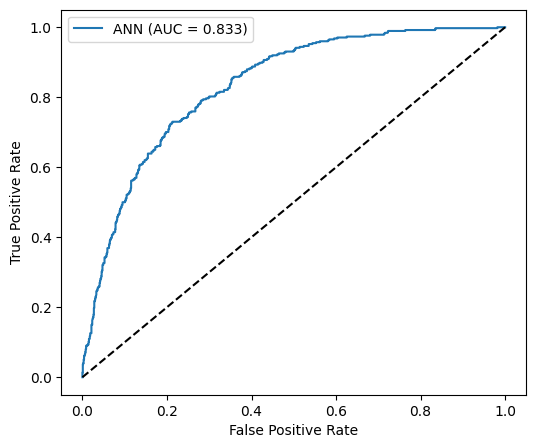

In [40]:
fpr, tpr, _ = roc_curve(y_test, y_prob_ann)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'ANN (AUC = {roc_auc_score(y_test, y_prob_ann):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

# ***ANN vs Classical ML***

In [41]:
ann_row = {
    "Model": "ANN (Keras)",
    "Best Params": "64-32-16, dropout 0.3",
    "Accuracy": accuracy_score(y_test, y_pred_ann),
    "Precision": precision_score(y_test, y_pred_ann),
    "Recall": recall_score(y_test, y_pred_ann),
    "F1": f1_score(y_test, y_pred_ann),
    "ROC-AUC": roc_auc_score(y_test, y_prob_ann)
}

comparison_df = pd.concat([results_df, pd.DataFrame([ann_row])], ignore_index=True)
comparison_df = comparison_df.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)
comparison_df

,Model,Best Params,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.733475,0.499190,0.823529,0.621594,0.840837
1,GradientBoosting,"{'learning_rate': 0.05, 'n_estimators': 100}",0.793177,0.637874,0.513369,0.568889,0.838484
2,LightGBM,"{'learning_rate': 0.05, 'n_estimators': 100}",0.744136,0.512238,0.783422,0.619450,0.836049
3,LogisticRegression,{'C': 10},0.724236,0.488487,0.794118,0.604888,0.834511
4,RandomForest,"{'max_depth': 5, 'n_estimators': 400}",0.717839,0.481054,0.780749,0.595311,0.833910
5,ANN (Keras),"64-32-16, dropout 0.3",0.721393,0.485437,0.802139,0.604839,0.832712
6,DecisionTree,{'max_depth': 5},0.733475,0.499160,0.794118,0.613003,0.827567
7,SVC,{'C': 0.1},0.729211,0.494215,0.799465,0.610827,0.821838
8,KNN,{'n_neighbors': 15},0.771855,0.573816,0.550802,0.562074,0.815421


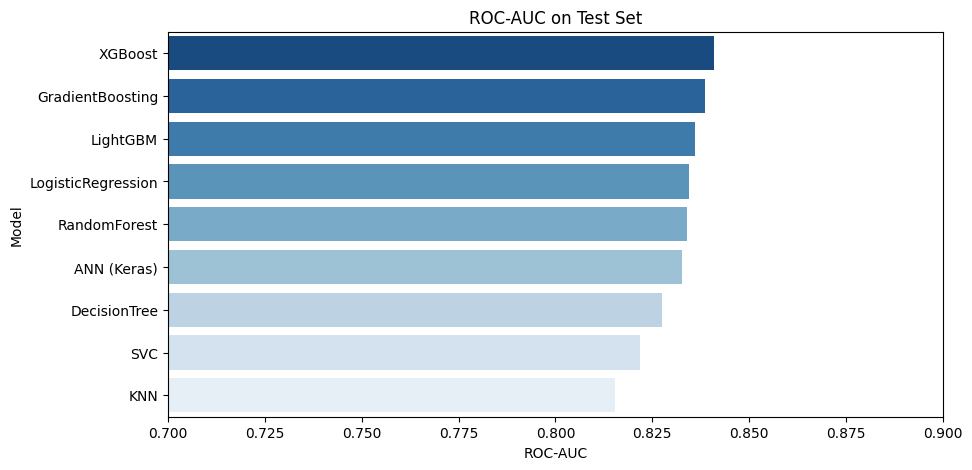

In [42]:
plt.figure(figsize=(10,5))
sns.barplot(x='ROC-AUC', y='Model', data=comparison_df, palette='Blues_r')
plt.xlim(0.7, 0.9)
plt.title('ROC-AUC on Test Set')
plt.show()